In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt

import glob

In [2]:
dir_list = sorted(glob.glob("/scratch/network/users/lb25v444/out_data/mcmc_22_N4_beta0p7_3x1M/job_21347214/run*"))
dir_list

['/scratch/network/users/lb25v444/out_data/mcmc_22_N4_beta0p7_3x1M/job_21347214/run_0',
 '/scratch/network/users/lb25v444/out_data/mcmc_22_N4_beta0p7_3x1M/job_21347214/run_1',
 '/scratch/network/users/lb25v444/out_data/mcmc_22_N4_beta0p7_3x1M/job_21347214/run_2']

In [6]:
gen_df  = "dati.dat"
topo_df = "topo.dat"

In [7]:
gen_data = []
topo_data = []

for d in dir_list[:]:
   gen_data.append(np.loadtxt(os.path.join(d,gen_df))[:])
   topo_data.append(np.loadtxt(os.path.join(d,topo_df))[:]) 

In [8]:
gen_data  = np.concatenate(gen_data, axis=0)
topo_data = np.concatenate(topo_data, axis=0)

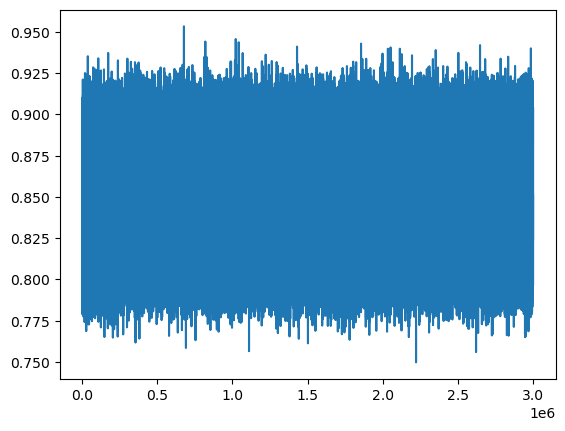

In [9]:
plt.plot(gen_data[:,1])

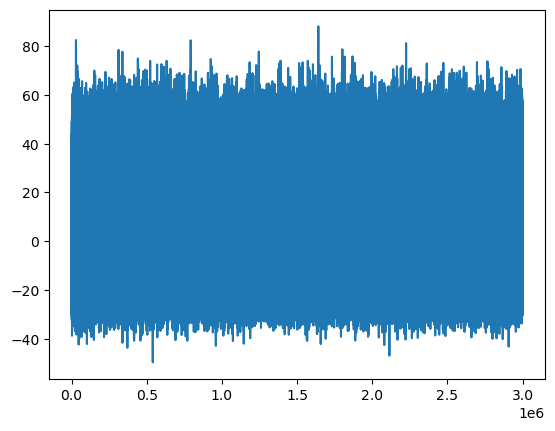

In [10]:
plt.plot(gen_data[:,2])

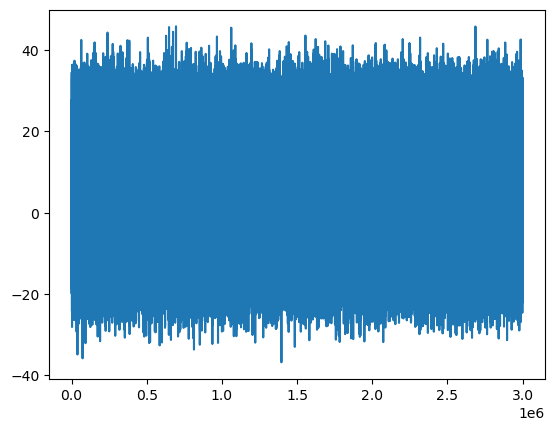

In [11]:
plt.plot(gen_data[:,3])

In [13]:
L = 22
k = 2*np.pi / L

In [19]:
g0 =np.mean(gen_data[:,2])
gk = np.mean(gen_data[:,3])

In [21]:
xi_L2 = 1 / (4 * np.sin(k/2)**2) * (g0/gk - 1.)
print(f"xi_L^2={xi_L2}")
print(f"xi_L={np.sqrt(xi_L2)}")

xi_L^2=3.1750738105960075
xi_L=1.7818736797528627


In [31]:
topo_data[:,2].shape

(33000000,)

In [33]:
c_step = 3
n_cool_step = 50     # number of cooling steps 
meas_cool_every = 5
skip_topo = n_cool_step // meas_cool_every + 1

obs = topo_data[c_step::skip_topo,2]

avg_obs = np.mean(obs)
print(avg_obs)

avg_obs = np.mean(obs**2)
print(avg_obs)


0.0011686666666666672
2.4842613333333334


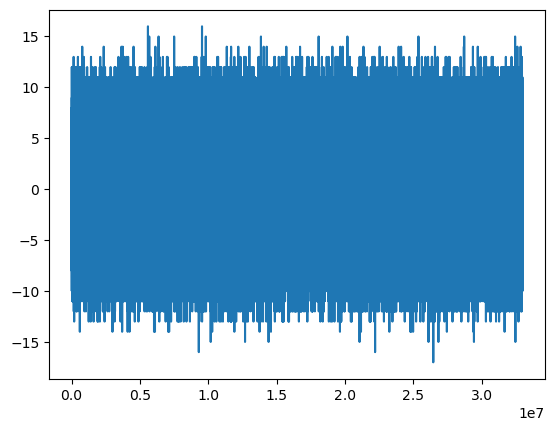

In [30]:
plt.plot(topo_data[:,2])